# Centrality concentration features (Week 4)

**Owner:** Salah · **Task:** add centrality concentration metrics to the network features · **Code:** `src/centrality.py`

**Question:** is influence in the stock network spread across many stocks, or concentrated in a few hubs, and does concentration rise *before* stress episodes?

**Network:** the team's recommended graph from `src/clustering.py`: residual returns after removing the equal-weighted market move, strongest 5% of positive links, weighted by correlation. Same graph as `features/clusters_market_adjusted_20d.parquet`. Every measure is computed over **all** stocks in the window, including unlinked ones, so values are comparable across windows.

| Measure | Meaning |
|---|---|
| `strength_gini` | Gini of weighted degree (0 = all stocks equally connected, 1 = one hub) |
| `strength_top10` | share of all link weight held by the top 10% of stocks |
| `degree_central` | Freeman degree centralization (0 = even, 1 = star) |
| `evc_top10` | share of eigenvector centrality in the top 10% of stocks |
| `raw_evc_eff_share` | check with no graph: effective share of stocks in the leading eigenvector of the raw correlation matrix |

Windows are trailing 60 trading days every 5 days (same dates as `features/connectedness_60d.parquet`), so a value dated t uses data up to t only.

**Before running:** the shared `data/processed/` folder from the team Drive. Runtime is about 1 minute.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import centrality as ce, returns as rt

PROC = ROOT / "data" / "processed"
MEASURES = ["strength_gini", "strength_top10", "degree_central", "evc_top10", "raw_evc_eff_share"]

## 1. Compute the features

In [2]:
rets = rt.load_returns()
feats, hubs = ce.centrality_over_time(rets)
print(f"{len(feats)} windows, {feats.index[0].date()} to {feats.index[-1].date()}")
feats.describe().round(3).T

1086 windows, 2005-04-06 to 2026-10-28


,count,mean,std,min,25%,50%,75%,max
strength_gini,1086.0,0.412,0.077,0.230,0.364,0.407,0.455,0.616
strength_top10,1086.0,0.278,0.042,0.192,0.251,0.271,0.300,0.408
degree_central,1086.0,0.112,0.028,0.056,0.091,0.108,0.128,0.198
evc_top10,1086.0,0.883,0.076,0.606,0.833,0.896,0.942,0.999
raw_evc_eff_share,1086.0,0.770,0.110,0.392,0.700,0.795,0.847,0.971
n_stocks,1086.0,383.463,70.513,263.000,327.000,374.000,451.000,499.000


## 2. Over time, with the stress episodes shaded

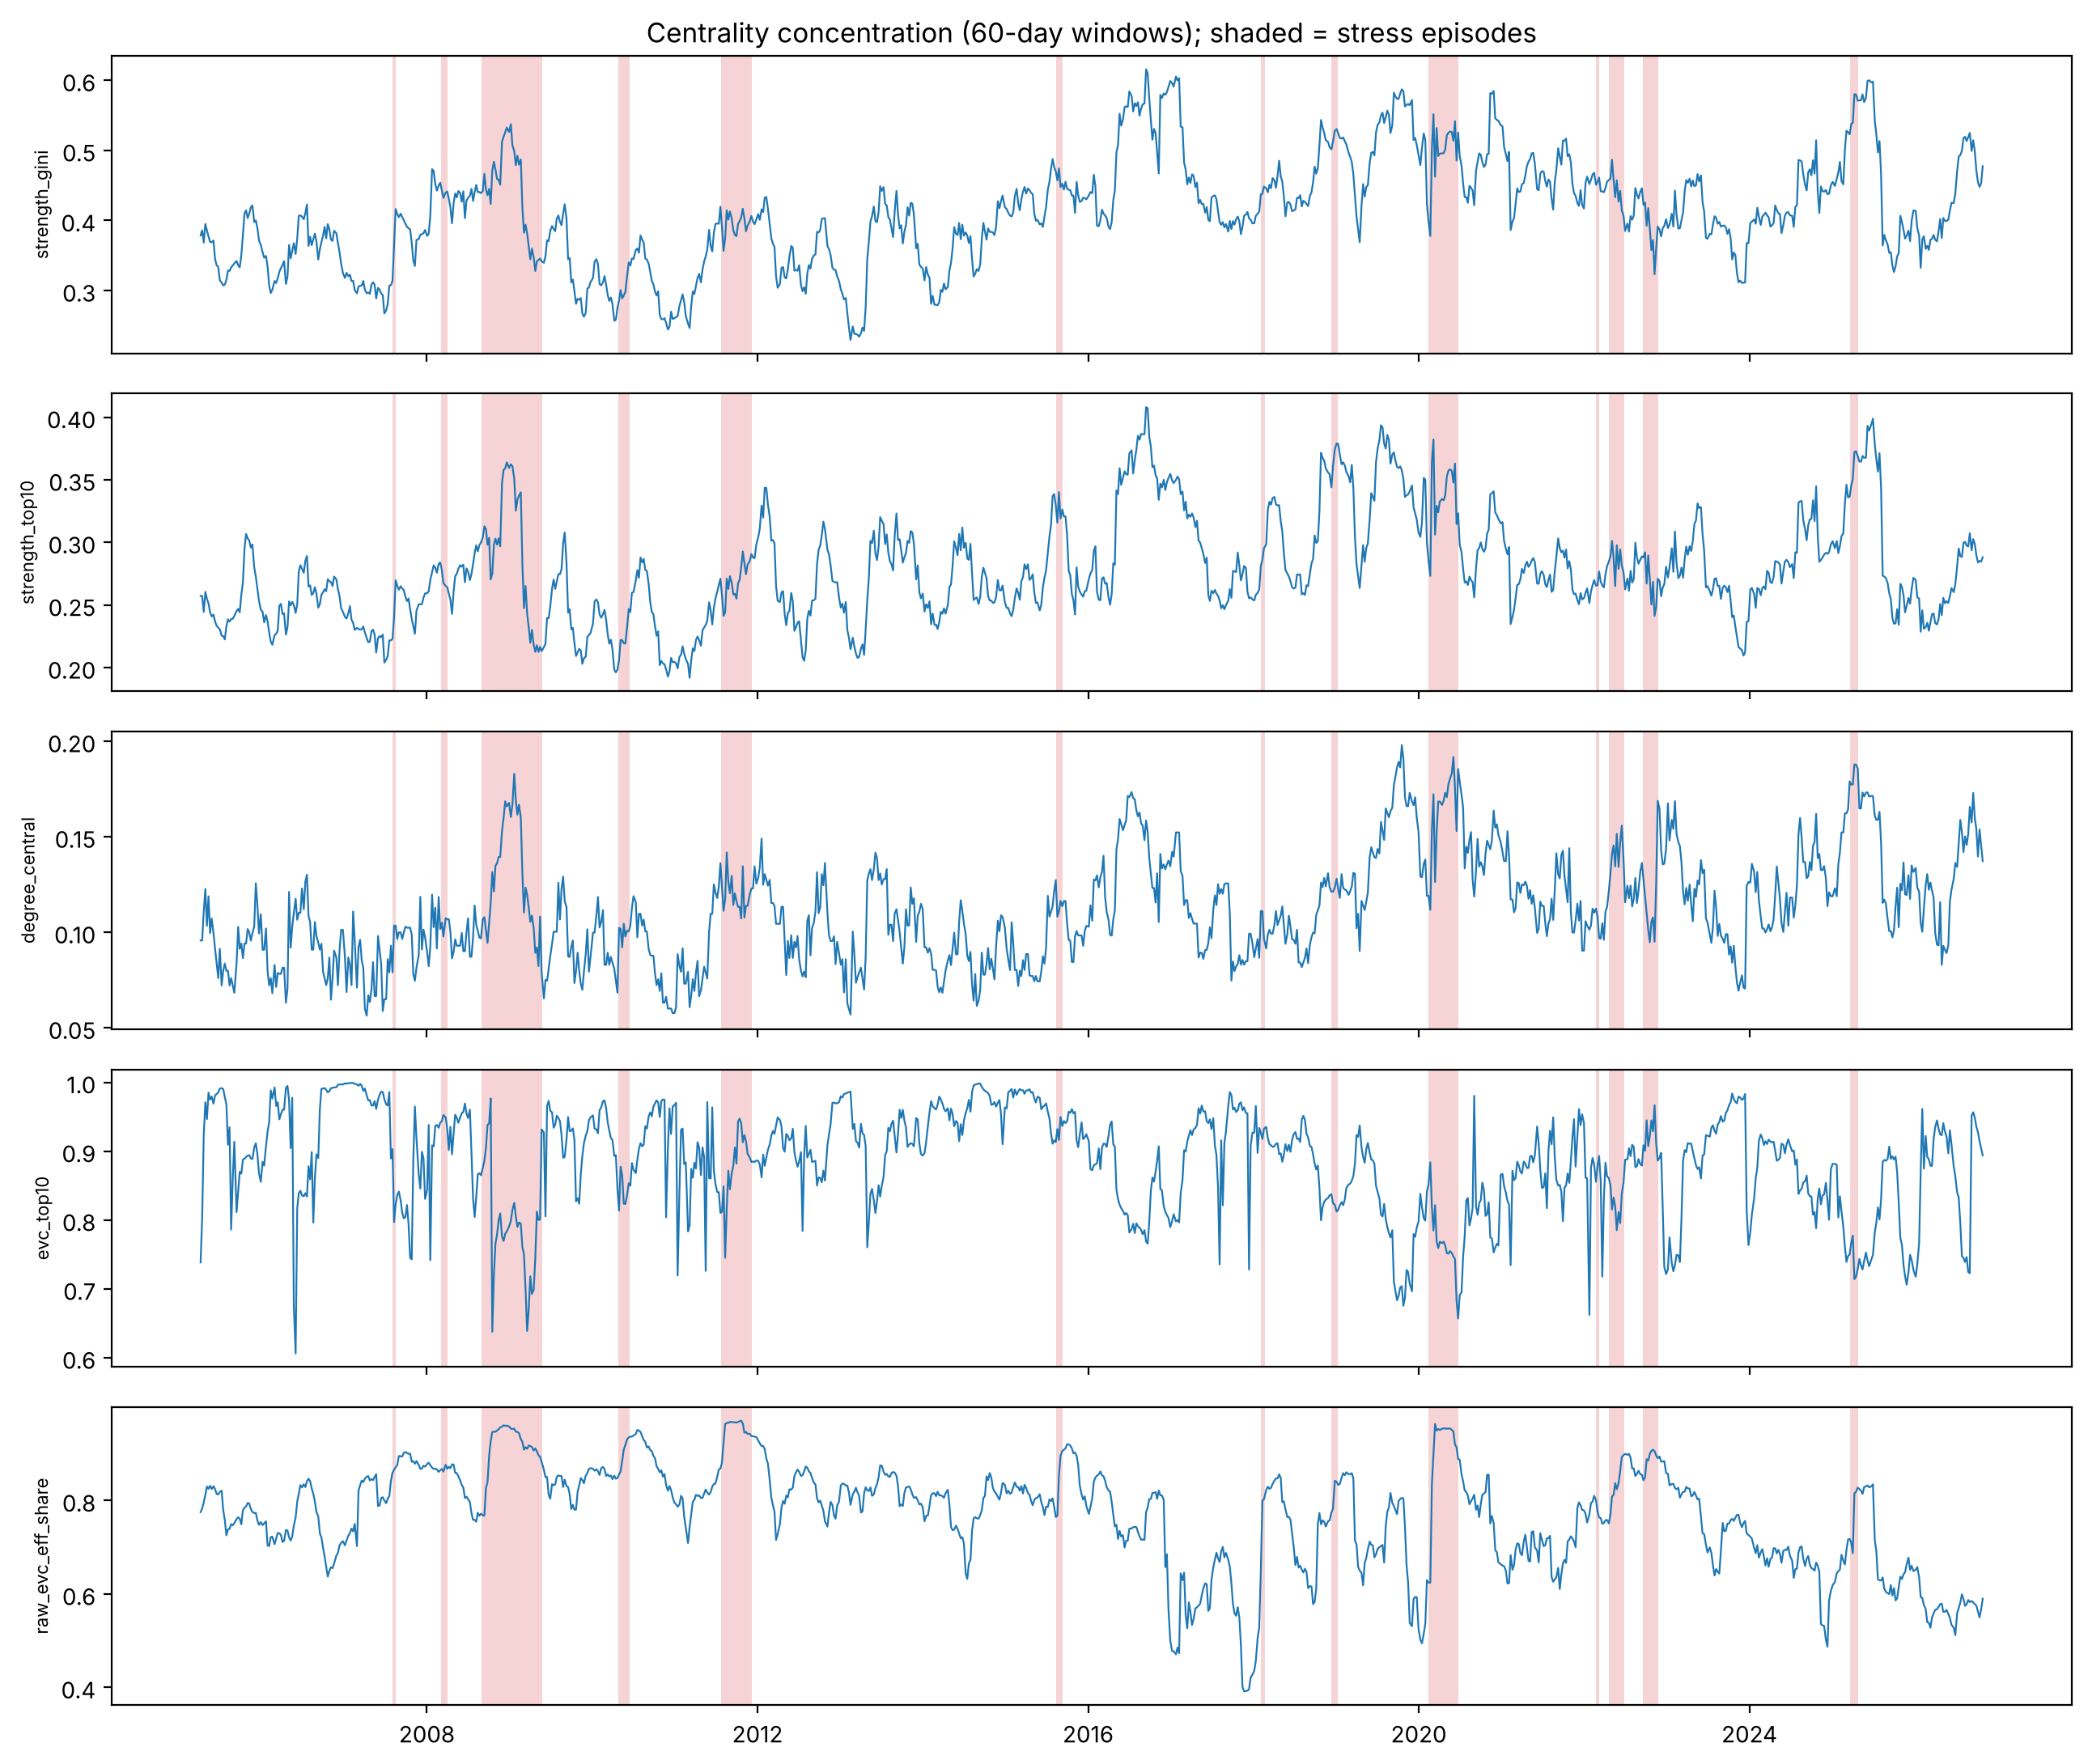

In [3]:
episodes = pd.read_csv(PROC / "stress_periods.csv", parse_dates=["start", "end"])
fig, axes = plt.subplots(len(MEASURES), 1, figsize=(13, 11), sharex=True)
for ax, m in zip(axes, MEASURES):
    ax.plot(feats.index, feats[m], lw=0.8)
    ax.set_ylabel(m, fontsize=8)
    for _, e in episodes.iterrows():
        ax.axvspan(e["start"], e["end"], color="tab:red", alpha=0.2, lw=0)
axes[0].set_title("Centrality concentration (60-day windows); shaded = stress episodes")
plt.tight_layout(); plt.show()

## 3. Is this new information, or a copy of the average correlation?

Rank correlation with the existing connectedness features. Values near ±1 mean the measure adds little.

In [4]:
conn = pd.read_parquet(PROC / "features" / "connectedness_60d.parquet")
joined = feats.join(conn[["avg_corr", "pc1_share", "absorption"]], how="inner")
print(f"{len(joined)} matching dates")
redundancy = joined.corr(method="spearman").loc[MEASURES, ["avg_corr", "pc1_share", "absorption"]].round(2)
display(redundancy)
display(joined[MEASURES].corr(method="spearman").round(2))

1086 matching dates


,avg_corr,pc1_share,absorption
strength_gini,-0.04,-0.00,0.46
strength_top10,0.02,0.05,0.36
degree_central,0.06,0.09,0.48
evc_top10,-0.12,-0.15,-0.33
raw_evc_eff_share,0.95,0.92,-0.19


,strength_gini,strength_top10,degree_central,evc_top10,raw_evc_eff_share
strength_gini,1.00,0.87,0.73,-0.52,-0.17
strength_top10,0.87,1.00,0.73,-0.46,-0.11
degree_central,0.73,0.73,1.00,-0.72,-0.06
evc_top10,-0.52,-0.46,-0.72,1.00,-0.02
raw_evc_eff_share,-0.17,-0.11,-0.06,-0.02,1.00


## 4. Calm vs stress

Average value inside and outside the labeled stress episodes. The labels use future data (centered window), which is fine here because this is evaluation, not a model input.

In [5]:
labels = pd.read_parquet(PROC / "stress_labels_daily.parquet")["stress"]
by_label = feats[MEASURES].groupby(labels.reindex(feats.index)).mean().round(3)
by_label.index = by_label.index.map({0.0: "calm", 1.0: "stress"})
by_label

,strength_gini,strength_top10,degree_central,evc_top10,raw_evc_eff_share
stress,,,,,
calm,0.408,0.277,0.11,0.89,0.754
stress,0.438,0.293,0.13,0.83,0.893


## 5. Behavior before each episode starts

Each measure is turned into a **point-in-time z-score**: its value minus the mean of the previous 52 windows (about one year), divided by their standard deviation. Only past windows are used. Then we line up the 13 episodes on their start date and look at the median z-score from 60 trading days before to 40 after. `avg_corr` is shown for comparison.

,strength_gini,strength_top10,degree_central,evc_top10,avg_corr
trading days from episode start,,,,,
-60,0.14,-0.18,-0.36,0.14,-0.11
-55,-0.06,-0.20,-0.31,0.28,-0.35
-50,0.01,-0.18,0.41,0.34,-0.36
-45,0.06,-0.09,0.01,0.50,-0.55
-40,-0.13,0.08,-0.22,0.20,-0.01
-35,-0.15,-0.39,-0.27,-0.34,0.23
-30,0.03,0.14,-0.06,0.07,0.34
-25,-0.08,0.60,0.59,-0.49,0.22
-20,0.21,0.87,0.00,-0.12,0.29


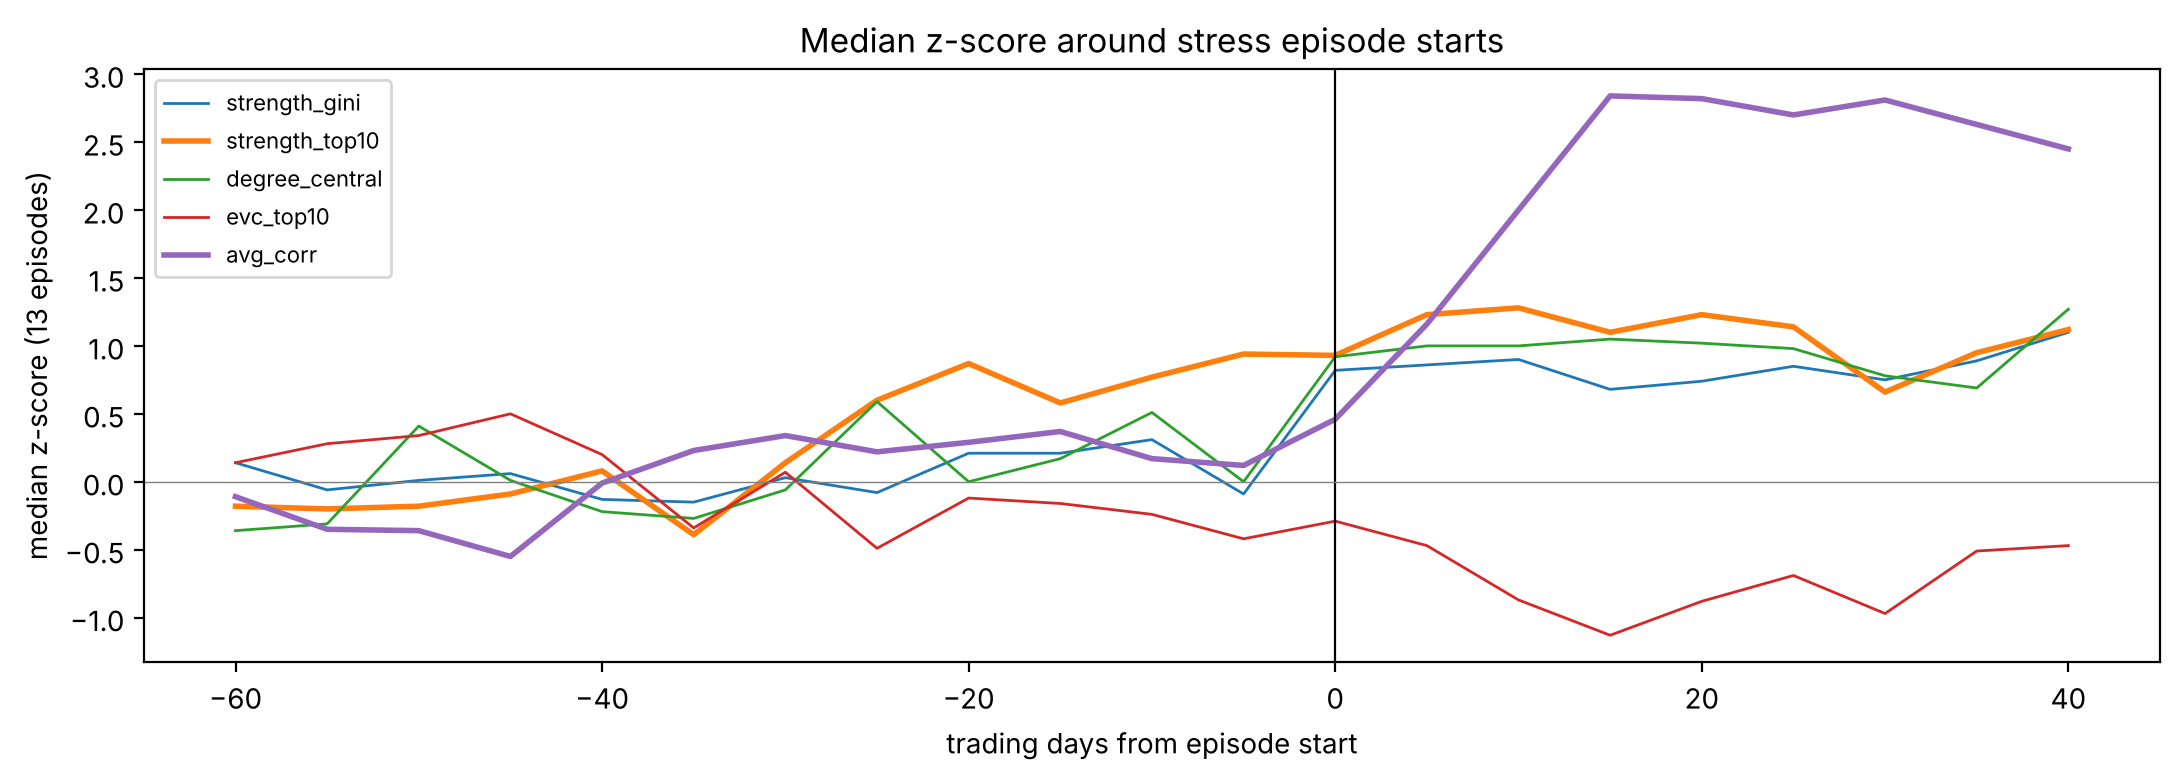

In [6]:
cols = MEASURES[:4] + ["avg_corr"]
past = joined[cols].rolling(52, min_periods=40)
z = (joined[cols] - past.mean().shift(1)) / past.std().shift(1)

offsets = range(-12, 9)   # in windows of 5 trading days
paths = {}
for _, e in episodes.iterrows():
    p = z.index.searchsorted(e["start"])
    paths[e["name"]] = pd.DataFrame({o * 5: z.iloc[p + o] for o in offsets if 0 <= p + o < len(z)}).T

event = pd.concat(paths).groupby(level=1).median().round(2)
event.index.name = "trading days from episode start"
display(event)

fig, ax = plt.subplots(figsize=(11, 4))
for c in cols:
    ax.plot(event.index, event[c], label=c, lw=2 if c in ("strength_top10", "avg_corr") else 1)
ax.axvline(0, color="black", lw=0.8); ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("trading days from episode start"); ax.set_ylabel("median z-score (13 episodes)")
ax.legend(fontsize=8); ax.set_title("Median z-score around stress episode starts")
plt.tight_layout(); plt.show()

In [7]:
# Per episode: mean z-score over the 60 trading days before the start
pre = pd.DataFrame({
    name: path.loc[[o for o in path.index if o < 0]].mean() for name, path in paths.items()
}).T.round(2)
display(pre)
print("Episodes with mean pre-start z > 0.5:")
print((pre > 0.5).sum().to_string())

,strength_gini,strength_top10,degree_central,evc_top10,avg_corr
Aug 2007 credit and quant-fund stress,-1.24,-1.49,-0.58,0.08,0.74
Bear Stearns,1.68,1.68,0.85,-0.34,0.56
Global financial crisis (Lehman),0.77,1.37,0.14,0.05,-1.47
Flash crash and first euro-area debt stress,-1.16,-0.67,-0.60,0.50,-0.71
"U.S. debt ceiling, S&P downgrade and euro-area debt crisis",1.58,0.61,1.15,-0.57,-0.57
China devaluation selloff,0.97,1.37,1.06,-1.43,-0.20
Feb 2018 volatility spike,-0.72,-0.87,-0.95,0.30,-1.95
Q4 2018 selloff,2.27,1.56,1.80,-1.61,-0.03
COVID-19 crash,-0.22,-0.67,0.09,-0.30,-1.57
Russia's invasion of Ukraine,-0.51,-0.88,-0.93,0.20,1.51


Episodes with mean pre-start z > 0.5:
strength_gini     6
strength_top10    6
degree_central    5
evc_top10         0
avg_corr          5


## 6. Who are the hubs?

The 10 most connected stocks in the window ending just before selected episode starts.

In [8]:
for d in ["2007-08-03", "2008-08-29", "2011-07-25", "2020-02-14"]:
    last = hubs.loc[hubs["date"] < d, "date"].max()
    print(d, "| window ending", last.date(), "|", ", ".join(hubs.loc[hubs["date"] == last, "ticker"]))

2007-08-03 | window ending 2007-08-02 | SO, WFC, PCG, FITB, AFL, CINF, DUK, ED, FE, XEL
2008-08-29 | window ending 2008-08-27 | XOM, NOV, EXC, COP, SLB, FLR, CVX, CNX, FCX, FE
2011-07-25 | window ending 2011-07-21 | NEE, ED, D, DUK, XEL, SO, WEC, DTE, PNW, SRE


2020-02-14 | window ending 2020-02-13 | AWK, ETR, UDR, PSA, AIV, WEC, NEE, CMS, AEP, XEL


## 7. Findings

All numbers come from the outputs above (Sections 3 to 6).

1. **The graph measures are new information.** `strength_gini`, `strength_top10` and `degree_central` have rank correlations between −0.04 and 0.06 with `avg_corr` (Section 3). The no-graph check, `raw_evc_eff_share`, is 0.95 rank-correlated with `avg_corr`, so on raw correlations "concentration" is just the market moving together. That confirms the market adjustment is needed, and `raw_evc_eff_share` should not be used as a model feature next to `avg_corr`.
2. **Concentration is higher in stress.** Weighted-degree Gini averages 0.438 in stress vs 0.408 in calm, and the top-10% share 0.293 vs 0.277 (Section 4). Eigenvector concentration (`evc_top10`) goes the other way, 0.83 vs 0.89: in stress, influence spreads beyond the single tightest group.
3. **`strength_top10` tends to rise before episodes start.** Its median z-score across the 13 episodes is 0.6 to 0.94 from 25 trading days before the start, while `avg_corr` stays between 0.12 and 0.37 until the start and jumps afterward (Section 5).
4. **It is inconsistent across episodes, but complements `avg_corr`.** `strength_top10` averaged z > 0.5 before 6 of 13 episodes (Bear Stearns, Lehman, 2011, 2015 China, Q4 2018, 2025 tariffs); `avg_corr` did before 5 (Aug 2007, Bear Stearns, 2022 Russia and both 2022 legs). Only Bear Stearns is in both, so together they cover 10 of 13. None of the measures rose before the three sudden shocks: the 2010 flash crash, Feb 2018 and COVID.
5. **Hubs are mostly utilities and energy, not banks** (Section 6). Before 2011 and 2020 the top 10 are all utilities or utility-like REITs; before Lehman they are oil and gas. In market-adjusted networks the tightest sector becomes the hub, so concentration measures how cohesive one sector is relative to the rest, not financial contagion specifically.
6. **Caveats.** 13 episodes is a small sample and these are medians, not a tested lead time (Week 6). The 2022 episodes start within 60 trading days of the previous one, so their "before" period overlaps earlier stress. The 0.5 cutoff is an arbitrary EDA choice.

**Recommendation for Week 5 features:** use `strength_top10` (or `strength_gini`, they are 0.87 rank-correlated, so not both) alongside `avg_corr`. Drop `raw_evc_eff_share`. Keep `evc_top10` and `degree_central` for the report only.

## 8. Save

In [9]:
out = PROC / "features"
out.mkdir(parents=True, exist_ok=True)
feats.to_parquet(out / "centrality_60d.parquet")
hubs.to_parquet(out / "centrality_hubs_60d.parquet", index=False)
print("Saved features/centrality_60d.parquet and features/centrality_hubs_60d.parquet")

Saved features/centrality_60d.parquet and features/centrality_hubs_60d.parquet
